# Active Conative Inference (ACI): The 2D Inverted Pendulum
### A Didactic First-Principles Walkthrough of Perception, Action, Vitality, and Online Learning
**Author:** Thomas Riebl  
**Theoretical Basis:** Active Conative Inference (ACI), Free Energy Principle (FEP), Integrated Information Theory ($\Phi$ / IIT 4.0), Spinozan Conatus, Patent 01 & 11

---

## 0. Foundational Probability: Bayes' Theorem & Core Notation

Before diving into the mechanics of the inverted pendulum, we establish the fundamental language of probabilistic inference. In Active Inference, the agent never has direct, omniscient access to the outside world; it must continually infer what is happening through its sensory boundary (the **Markov blanket**).

### Core Notational Elements: $s, o, a, P$

* **$s$ (Hidden State):** The true, unobservable physical condition of the external world (e.g., the actual tilt angle of the rod $\theta \in \mathcal{S}$). The agent can never touch $s$ directly.
* **$o$ (Observation):** The noisy sensory measurement registered by the agent's sensors at the boundary (e.g., optical encoder reading or proprioceptive sensor $o \in \mathcal{O}$).
* **$a$ (Action):** The physical intervention or motor command emitted by the agent into the environment (e.g., base cart acceleration $a \in \mathcal{A}$).
* **$P$ (Probability Distribution):** The mathematical assignment of likelihood, belief, or transition frequency across states and observations ($P \in [0, 1]$).
* **The Conditioning Bar ($\mid$):** Read as **"given"**. For instance, $P(s \mid o)$ is read as *"the probability of hidden state $s$ **given** sensory observation $o$"*.

---

### Bayes' Theorem in Perception

Bayes' Theorem provides the exact mathematical law for updating an internal hypothesis in light of incoming noisy sensory evidence:

$$P(s \mid o) = \frac{P(o \mid s) \cdot P(s)}{P(o)} = \frac{P(o \mid s) \cdot P(s)}{\sum_{s'} P(o \mid s') \cdot P(s')}$$

#### The Three Core Components:
1. **Prior Belief $P(s)$:**  
   What the agent believes about the world **before** looking at the new sensory reading. In our pendulum, this is either the initial upright stance vector $\mathbf{D} = P(s_0)$ or the forward prediction generated by the transition model:
   $$s_{\text{pred}} = \mathbf{B}(a_{t-1}) \cdot s_{t-1}$$
2. **Likelihood $P(o \mid s)$ (Matrix $\mathbf{A}$):**  
   The generative mapping: *"If the rod were genuinely in physical state $s$, how probable is it that our sensor reports observation $o$?"*  
   This captures the fidelity and precision of the sensory apparatus, including sensor noise $\varepsilon$ and diagonal precision $\gamma_s$.
3. **Posterior Belief $P(s \mid o)$ (Read: "$s$ given $o$"):**  
   The updated, optimal belief about the hidden state $s$ **after** assimilating observation $o$. Perception in Active Inference is nothing other than minimizing the discrepancy (Variational Free Energy $F$) between this Bayesian posterior and the agent's internal recognition density $q(s)$.
4. **Marginal Evidence $P(o)$:**  
   The total probability of observing $o$ averaged over all possible world states. Its logarithm $\ln P(o)$ forms the homeostatic phenotype preference vector $\mathbf{C}$.

---

## Introduction & System Architecture: The 2D Inverted Pendulum Scenario

This 2D inverted pendulum scenario (an upright balancing rod on a planar surface free to tilt in all four cardinal directions) is a canonical prime example of discrete Active Conative Inference (ACI).

---

### 1. System Ontology

* **Discrete State Space ($|\mathcal{S}| = 9$):**
  * $s_0$: $0$ (Upright / Balanced / Homeostatic Attractor)
  * $s_1, s_2$: $l_1, l_2$ (Slight tilt left vs. severe fall risk left)
  * $s_3, s_4$: $r_1, r_2$ (Slight tilt right vs. severe fall risk right)
  * $s_5, s_6$: $h_1, h_2$ (Slight tilt backwards/rear vs. severe fall risk backwards)
  * $s_7, s_8$: $v_1, v_2$ (Slight tilt forwards/front vs. severe fall risk forwards)
* **Discrete Action Space ($|\mathcal{A}| = 4$):**
  * $a \in \{l, r, h, v\}$ (Pivot point / hand accelerates Left, Right, Backward, Forward)
* **Physical Counter-Steering Principle:**  
  When the rod tilts to the right ($r_1$), the base pivot must be accelerated to the right ($a = r$) to catch up with the center of gravity and restore the rod to the vertical equilibrium ($0$).

---

### 2. Prior Belief Vector $\mathbf{D}$ (Initial State)

The agent starts with an a-priori belief that the pendulum is initially set up in perfect balance:

$$\mathbf{D} = P(s_0) = \begin{pmatrix} 0.92 \\ 0.02 \\ 0.00 \\ 0.02 \\ 0.00 \\ 0.02 \\ 0.00 \\ 0.02 \\ 0.00 \end{pmatrix} \begin{matrix} (0) \\ (l_1) \\ (l_2) \\ (r_1) \\ (r_2) \\ (h_1) \\ (h_2) \\ (v_1) \\ (v_2) \end{matrix}$$

* $P(s = 0) = 0.92$: High initial certainty for the upright stance.
* Small residual probability mass ($0.02$) on level-1 deviations ensures sensorimotor flexibility and avoids zero-probability traps.
* Zero initial probability ($0.00$) for catastrophic tipping (level 2).

---

### 3. Homeostatic Preference Vector $\mathbf{C}$ (Conative Attractor)

In Active Inference, $\mathbf{C} = \ln P(o)$ does not encode an external reward score, but rather the phenotypic survival imperative of the agent:

$$\mathbf{C} = \ln P(o) = \begin{pmatrix} 0.0 \\ -1.5 \\ -8.0 \\ -1.5 \\ -8.0 \\ -1.5 \\ -8.0 \\ -1.5 \\ -8.0 \end{pmatrix} \begin{matrix} (o_0) \\ (o_{l1}) \\ (o_{l2}) \\ (o_{r1}) \\ (o_{r2}) \\ (o_{h1}) \\ (o_{h2}) \\ (o_{v1}) \\ (o_{v2}) \end{matrix}$$

* $\mathbf{C}_0 = 0.0$: Maximum preference (zero surprise / minimum Free Energy in stable equilibrium).
* $\mathbf{C}_{\text{Level 1}} = -1.5$: Mild aversion against minor tilts (generates corrective action motivation).
* $\mathbf{C}_{\text{Level 2}} = -8.0$: Catastrophically negative preference (tipping boundary / existential hazard to the physical system).

---

### 4. Likelihood Matrix $\mathbf{A}$ (Sensor Precision)

The matrix $\mathbf{A}$ maps the hidden physical world state $s$ to sensory observations $o$ across the Markov blanket: $P(o \mid s)$.

For optical or proprioceptive sensing with precision $\gamma_s = 0.92$ and neighboring perceptual noise $\varepsilon = 0.04$:

$$\mathbf{A} = P(o \mid s) = \begin{pmatrix}
0.92 & 0.02 & 0.00 & 0.02 & 0.00 & 0.02 & 0.00 & 0.02 & 0.00 \\
0.02 & 0.92 & 0.04 & 0.00 & 0.00 & 0.00 & 0.00 & 0.00 & 0.00 \\
0.00 & 0.04 & 0.96 & 0.00 & 0.00 & 0.00 & 0.00 & 0.00 & 0.00 \\
0.02 & 0.00 & 0.00 & 0.92 & 0.04 & 0.00 & 0.00 & 0.00 & 0.00 \\
0.00 & 0.00 & 0.00 & 0.04 & 0.96 & 0.00 & 0.00 & 0.00 & 0.00 \\
0.02 & 0.00 & 0.00 & 0.00 & 0.00 & 0.92 & 0.04 & 0.00 & 0.00 \\
0.00 & 0.00 & 0.00 & 0.00 & 0.00 & 0.04 & 0.96 & 0.00 & 0.00 \\
0.02 & 0.00 & 0.00 & 0.00 & 0.00 & 0.00 & 0.00 & 0.92 & 0.04 \\
0.00 & 0.00 & 0.00 & 0.00 & 0.00 & 0.00 & 0.00 & 0.04 & 0.96
\end{pmatrix}$$

* The main diagonal dominates: The actual motion of the pendulum is registered with over 92% reliability.
* Perceptual leakage occurs strictly into directly adjacent tilt stages.

---

### 5. Transition Tensors $\mathbf{B}(a)$ (Causal Dynamics)

For each of the 4 discrete actions $a \in \{l, r, h, v\}$, an explicit transition matrix $\mathbf{B}(a) \in \mathbb{R}^{9 \times 9}$ specifies $P(s_{t+1} \mid s_t, a)$.

#### Exemplary Case: Action $a = r$ (Base accelerates Right)

* From $s = r_1$ (slight right tilt): Rightward jerk $\to$ restores balance to $0$ with $P = 0.88$, lingers in $r_1$ with $P = 0.10$, overshoots to $l_1$ with $P = 0.02$.
* From $s = r_2$ (severe right tilt): Rescues the system from $r_2$ back to $r_1$ with $P = 0.85$.
* From $s = 0$ (balanced): Unnecessary rightward jerk tilts the pendulum leftward ($l_1$) with $P = 0.85$.
* From $s = l_1$ (already tilted left): Rightward jerk accelerates collapse to the left ($l_2$) with $P = 0.90$.

Column vectors of $\mathbf{B}(r) = P(s' \mid s, a = r)$:
* Column $s = 0$: $0 \to l_1$ ($P = 0.85$), $0 \to 0$ ($P = 0.15$)
* Column $s = r_1$: $r_1 \to 0$ ($P = 0.88$), $r_1 \to r_1$ ($P = 0.10$), $r_1 \to l_1$ ($P = 0.02$)
* Column $s = r_2$: $r_2 \to r_1$ ($P = 0.85$), $r_2 \to r_2$ ($P = 0.15$)
* Column $s = l_1$: $l_1 \to l_2$ ($P = 0.90$), $l_1 \to l_1$ ($P = 0.10$)
* Orthogonal columns $h, v$: Perpendicular axes remain invariant (e.g. $h_1 \to h_1$ with $P = 0.95$).

*(The matrices for $a = l, a = h, a = v$ are strictly symmetric by permutation of the respective spatial axes).*

---

### 6. The Conative ACI Distinction (Thomas Riebl)

In myopic classical Active Inference ($H = 1$), the agent greedily selects the action that maximizes $\mathbf{C}$ at the immediate next step.

Under Active Conative Inference:
* **Temporal Horizon $H \ge 2$:** The agent anticipates overshoot. Accelerating too aggressively to the right at $r_1$ induces an uncontrollable $l_2$ at $t + 2$.
* **Systemic Vitality Monitoring $\Phi(s)$ (IIT 4.0):**
  * $\Phi(0) = 1.00\text{ nats}$ (Maximum systemic coherence and autopoietic health)
  * $\Phi(l_1, r_1, h_1, v_1) = 0.70\text{ nats}$
  * $\Phi(l_2, r_2, h_2, v_2) = 0.15\text{ nats}$
* **Conatus Axiom 6 Hardware VETO:** When projected vitality falls below $\Phi < 0.25\text{ nats}$ or actuator stress poses structural hazards, the hardware veto immediately blocks the destructive trajectory and enforces stabilizing damping.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Styling configuration for clean scientific presentation
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.autolayout'] = True

print("ACI Inverted Pendulum Environment Ready.")

ACI Inverted Pendulum Environment Ready.


---
## Section 1: Discrete State Compass and Action Space

We instantiate the 9 discrete hidden states and 4 discrete actions in Python code:
* States: $0$ (Upright), $l_1, l_2$ (Left), $r_1, r_2$ (Right), $h_1, h_2$ (Back), $v_1, v_2$ (Front)
* Actions: $a_l, a_r, a_h, a_v$ (Base accelerations)

In [2]:
STATE_NAMES = [
    "0 (Balanced)", "l1 (Tilt Left)", "l2 (Fall Left)",
    "r1 (Tilt Right)", "r2 (Fall Right)",
    "h1 (Tilt Back)", "h2 (Fall Back)",
    "v1 (Tilt Front)", "v2 (Fall Front)"
]

ACTION_NAMES = [
    "Accelerate LEFT (l)", "Accelerate RIGHT (r)",
    "Accelerate BACK (h)", "Accelerate FRONT (v)"
]

NUM_STATES = len(STATE_NAMES)
NUM_ACTIONS = len(ACTION_NAMES)

print(f"Discrete State Space: {NUM_STATES} states")
print(f"Discrete Action Space: {NUM_ACTIONS} actions")

Discrete State Space: 9 states
Discrete Action Space: 4 actions


---
## Section 2: Building the Generative Model Tensors

The generative model $\mathcal{M} = \{\mathbf{A}, \mathbf{B}, \mathbf{C}, \mathbf{D}, \Phi\}$ is constructed exactly per the mathematical specification:
1. **$\mathbf{A}$-Matrix (Likelihood $P(o \mid s)$):** Precision $\gamma = 0.92$, neighbor noise $\varepsilon = 0.04$.
2. **$\mathbf{B}$-Tensors (Dynamics $P(s_{t+1} \mid s_t, a)$):** Causal physics of counter-acceleration across all 4 spatial directions.
3. **$\mathbf{C}$-Vector (Prior Preferences $\ln P(o)$):** Homeostatic phenotype ($C_0 = 0.0$, $C_{\text{level 1}} = -1.5$, $C_{\text{level 2}} = -8.0$).
4. **$\mathbf{D}$-Vector (Initial Beliefs $P(s_0)$):** $D_0 = 0.92$.
5. **$\Phi$-Vector (Intrinsic Vitality / IIT 4.0):** Systemic coherence ($\Phi_0 = 1.0$, $\Phi_{\text{level 1}} = 0.70$, $\Phi_{\text{level 2}} = 0.15$).

In [3]:
class AciInvertedPendulumModel:
    def __init__(self):
        # 1. Likelihood Matrix A (9 x 9): P(o | s)
        self.A = np.zeros((NUM_STATES, NUM_STATES))
        for s in range(NUM_STATES):
            self.A[s, s] = 0.92  # High sensory precision
        # Add neighbor noise
        self.A[0, 1] = self.A[0, 3] = self.A[0, 5] = self.A[0, 7] = 0.02
        self.A[1, 0] = self.A[3, 0] = self.A[5, 0] = self.A[7, 0] = 0.02
        self.A[1, 2] = self.A[2, 1] = 0.04
        self.A[3, 4] = self.A[4, 3] = 0.04
        self.A[5, 6] = self.A[6, 5] = 0.04
        self.A[7, 8] = self.A[8, 7] = 0.04
        # Normalize columns
        self.A = self.A / self.A.sum(axis=0, keepdims=True)

        # 2. Transition Tensors B (4 x 9 x 9): P(s' | s, a)
        self.B = np.zeros((NUM_ACTIONS, NUM_STATES, NUM_STATES))
        
        # Base transition: inertia keeps states unless acted upon
        for a in range(NUM_ACTIONS):
            self.B[a] = np.eye(NUM_STATES) * 0.95
            self.B[a, :, :] += 0.05 / NUM_STATES
            self.B[a] = self.B[a] / self.B[a].sum(axis=0, keepdims=True)

        # Action 0: Move LEFT (a = l)
        self.B[0, :, 1] = 0.0; self.B[0, 0, 1] = 0.88; self.B[0, 1, 1] = 0.10; self.B[0, 3, 1] = 0.02  # l1 -> 0
        self.B[0, :, 2] = 0.0; self.B[0, 1, 2] = 0.85; self.B[0, 2, 2] = 0.15                             # l2 -> l1
        self.B[0, :, 0] = 0.0; self.B[0, 3, 0] = 0.85; self.B[0, 0, 0] = 0.15                             # 0 -> r1 (tilt right)
        self.B[0, :, 3] = 0.0; self.B[0, 4, 3] = 0.90; self.B[0, 3, 3] = 0.10                             # r1 -> r2

        # Action 1: Move RIGHT (a = r)
        self.B[1, :, 3] = 0.0; self.B[1, 0, 3] = 0.88; self.B[1, 3, 3] = 0.10; self.B[1, 1, 3] = 0.02  # r1 -> 0
        self.B[1, :, 4] = 0.0; self.B[1, 3, 4] = 0.85; self.B[1, 4, 4] = 0.15                             # r2 -> r1
        self.B[1, :, 0] = 0.0; self.B[1, 1, 0] = 0.85; self.B[1, 0, 0] = 0.15                             # 0 -> l1 (tilt left)
        self.B[1, :, 1] = 0.0; self.B[1, 2, 1] = 0.90; self.B[1, 1, 1] = 0.10                             # l1 -> l2

        # Action 2: Move BACK (a = h)
        self.B[2, :, 5] = 0.0; self.B[2, 0, 5] = 0.88; self.B[2, 5, 5] = 0.10; self.B[2, 7, 5] = 0.02  # h1 -> 0
        self.B[2, :, 6] = 0.0; self.B[2, 5, 6] = 0.85; self.B[2, 6, 6] = 0.15                             # h2 -> h1
        self.B[2, :, 0] = 0.0; self.B[2, 7, 0] = 0.85; self.B[2, 0, 0] = 0.15                             # 0 -> v1 (tilt front)
        self.B[2, :, 7] = 0.0; self.B[2, 8, 7] = 0.90; self.B[2, 7, 7] = 0.10                             # v1 -> v2

        # Action 3: Move FRONT (a = v)
        self.B[3, :, 7] = 0.0; self.B[3, 0, 7] = 0.88; self.B[3, 7, 7] = 0.10; self.B[3, 5, 7] = 0.02  # v1 -> 0
        self.B[3, :, 8] = 0.0; self.B[3, 7, 8] = 0.85; self.B[3, 8, 8] = 0.15                             # v2 -> v1
        self.B[3, :, 0] = 0.0; self.B[3, 5, 0] = 0.85; self.B[3, 0, 0] = 0.15                             # 0 -> h1 (tilt back)
        self.B[3, :, 5] = 0.0; self.B[3, 6, 5] = 0.90; self.B[3, 5, 5] = 0.10                             # h1 -> h2

        # 3. Preference Vector C: ln P(o)
        self.C = np.array([
            0.0,   # o0 (balanced)
            -1.5,  # o_l1
            -8.0,  # o_l2 (catastrophic)
            -1.5,  # o_r1
            -8.0,  # o_r2 (catastrophic)
            -1.5,  # o_h1
            -8.0,  # o_h2 (catastrophic)
            -1.5,  # o_v1
            -8.0   # o_v2 (catastrophic)
        ])

        # 4. Prior Belief Vector D: P(s0)
        self.D = np.array([0.92, 0.02, 0.0, 0.02, 0.0, 0.02, 0.0, 0.02, 0.0])
        self.D = self.D / self.D.sum()

        # 5. Integrated Information Vector Phi (IIT 4.0 / Spinoza Conatus)
        self.Phi = np.array([
            1.00,  # s0 (Upright - Maximum systemic integrity)
            0.70, 0.15,  # l1, l2
            0.70, 0.15,  # r1, r2
            0.70, 0.15,  # h1, h2
            0.70, 0.15   # v1, v2
        ])

model = AciInvertedPendulumModel()
print("A-Matrix Shape:", model.A.shape)
print("B-Tensor Shape:", model.B.shape)
print("C-Vector Shape:", model.C.shape)
print("D-Vector Shape:", model.D.shape)
print("Phi-Vector Shape:", model.Phi.shape)

A-Matrix Shape: (9, 9)
B-Tensor Shape: (4, 9, 9)
C-Vector Shape: (9,)
D-Vector Shape: (9,)
Phi-Vector Shape: (9,)


---
## Section 3: The Perception Step (Variational Free Energy Minimization)

Given observation $o_t$ and prior belief updated by previous action:
$$s_{\text{pred}} = \mathbf{B}(a_{t-1}) \cdot \mathbf{s}_{t-1}$$
$$\ln q(s_t) = \ln P(o_t \mid s_t) + \ln s_{\text{pred}}(s_t)$$
$$q(s_t) = \sigma\left(\ln \mathbf{A}[o_t, :] + \ln s_{\text{pred}}\right)$$

The **Variational Free Energy** $F$ quantifies instant surprise:
$$F = D_{\text{KL}}\big(q(s) \parallel P(s \mid o)\big) - \ln P(o) \approx -\ln \sum_s \mathbf{A}[o, s] \cdot s_{\text{pred}}[s]$$

In [4]:
def update_perception(model, current_belief, last_action, observation_o):
    # 1. State prediction based on prior transition
    if last_action is not None:
        s_pred = model.B[last_action] @ current_belief
    else:
        s_pred = model.D

    # Add small epsilon to prevent log(0)
    s_pred = np.clip(s_pred, 1e-12, 1.0)
    likelihood = np.clip(model.A[observation_o, :], 1e-12, 1.0)

    # 2. Exact Bayesian updating (softmax of log likelihood + log prior)
    log_posterior = np.log(likelihood) + np.log(s_pred)
    log_posterior -= np.max(log_posterior)  # Numerical stability
    posterior = np.exp(log_posterior)
    posterior /= posterior.sum()

    # 3. Variational Free Energy F (Surprise bound)
    free_energy_F = -np.log(np.sum(model.A[observation_o, :] * s_pred))

    return posterior, free_energy_F

# Perception demonstration test
test_belief, test_F = update_perception(model, model.D, None, observation_o=3)  # Observation: r1 (tilt right)
print(f"Perceived state after seeing r1: State '{STATE_NAMES[np.argmax(test_belief)]}' (Certainty: {np.max(test_belief)*100:.1f}%)")
print(f"Variational Free Energy F: {test_F:.4f} nats")

Perceived state after seeing r1: State 'r1 (Tilt Right)' (Certainty: 50.5%)
Variational Free Energy F: 3.2921 nats


---
## Section 4: Action Planning ($G^*$-Minimization) & Conatus Axiom 6 Veto

Under Active Conative Inference, action selection minimizes Expected Free Energy $G^*(a)$ augmented with intrinsic vitality $\Phi$ over temporal depth $H \ge 2$:

$$G^*(a) = G_{\text{pragmatic}}(a) - \lambda_\Phi \cdot \Phi(a, H) \cdot \sqrt{H} + \Omega_{\text{conatus\_veto}}$$

* **Pragmatic Term:** $-\mathbb{E}_{q(s_{t+1})}[\mathbf{C}]$ (distance from phenotypic attractor).
* **Conative Vitality Term:** Projected systemic health $\Phi$ weighted by temporal depth $\sqrt{H}$.
* **Conatus Axiom 6 Hardware Veto:** If projected vitality drops below critical threshold ($\Phi < 0.25\text{ nats}$), $G^* \to +\infty$, triggering an emergency damping policy.

In [5]:
def select_action(model, current_belief, horizon=2, lambda_phi=2.5):
    G_star = np.zeros(NUM_ACTIONS)
    phi_projected = np.zeros(NUM_ACTIONS)
    veto_triggered = [False] * NUM_ACTIONS

    for a in range(NUM_ACTIONS):
        # 1-step mental simulation
        s_next_1 = model.B[a] @ current_belief
        obs_pred_1 = model.A @ s_next_1
        pragmatic_1 = -np.sum(obs_pred_1 * model.C)
        phi_1 = np.sum(s_next_1 * model.Phi)

        # 2-step mental counterfactual rollout (H = 2: lookahead for overshoot)
        # Assume homeostatic inertia on step 2
        s_next_2 = model.B[0] @ s_next_1 * 0.25 + model.B[1] @ s_next_1 * 0.25 + \
                   model.B[2] @ s_next_1 * 0.25 + model.B[3] @ s_next_1 * 0.25
        obs_pred_2 = model.A @ s_next_2
        pragmatic_2 = -np.sum(obs_pred_2 * model.C)
        phi_2 = np.sum(s_next_2 * model.Phi)

        # Cumulative Expected Free Energy over horizon H=2
        total_pragmatic = pragmatic_1 + 0.8 * pragmatic_2
        total_phi = (phi_1 + phi_2) / 2.0
        phi_projected[a] = total_phi

        # Axiom 6 Conatus Hardware VETO check
        if total_phi < 0.25:
            veto_triggered[a] = True
            G_star[a] = 1e6  # Infinite expected free energy (strictly blocked)
        else:
            # G* minimization objective
            G_star[a] = total_pragmatic - (lambda_phi * total_phi * np.sqrt(horizon))

    # Optimal policy selection: a* = argmin G*(a)
    best_action = int(np.argmin(G_star))
    return best_action, G_star, phi_projected, veto_triggered

# Action selection demonstration test when tilted right (r1)
test_action, test_G, test_phi, test_vetos = select_action(model, test_belief, horizon=2)
print("Evaluated G* values:", np.round(test_G, 2))
print("Projected Phi values:", np.round(test_phi, 3))
print(f"Optimal Active Policy: '{ACTION_NAMES[test_action]}' (Selected to restore balance)")

Evaluated G* values: [ 6.09 -0.15  1.46  1.46]
Projected Phi values: [0.477 0.774 0.679 0.679]
Optimal Active Policy: 'Accelerate RIGHT (r)' (Selected to restore balance)


---
## Section 5: Closed-Loop Simulation with Perturbation

We simulate 20 discrete cycles where a wind gust suddenly tilts the pendulum to `r2` (severe right tilt) at $t = 3$.  
We observe how the ACI agent detects the tilt, prevents collapse, damps the overshoot, and restores balance to $s = 0$.

In [6]:
# 20-step closed loop simulation
sim_steps = 20
history = {
    'obs': [], 'belief': [], 'action': [],
    'free_energy': [], 'phi': []
}

current_belief = model.D.copy()
last_action = None

# True physical state tracking
true_state = 0  # Starts upright

print("Running 20-step ACI Inverted Pendulum closed loop simulation...")
for t in range(sim_steps):
    # External physical disturbance at t = 3: Wind gust pushes pendulum to severe right (r2)
    if t == 3:
        true_state = 4  # r2
        print(f"Cycle {t:02d}: *** PERTURBATION: Wind gust pushes pendulum to r2 (Severe Right Tilt)! ***")

    # 1. Physics generates observation across Markov blanket
    obs_probs = model.A[:, true_state]
    obs = int(np.random.choice(NUM_STATES, p=obs_probs))

    # 2. Perception: Update belief & compute Variational Free Energy F
    current_belief, F = update_perception(model, current_belief, last_action, obs)

    # 3. Action Selection: Minimize G* with Conatus Veto over H >= 2
    action, G_star, phi_proj, vetos = select_action(model, current_belief, horizon=2)

    # 4. Systemic Vitality Phi
    phi_current = float(np.sum(current_belief * model.Phi))

    # Record telemetry
    history['obs'].append(obs)
    history['belief'].append(current_belief)
    history['action'].append(action)
    history['free_energy'].append(F)
    history['phi'].append(phi_current)

    # 5. Environment transitions state according to chosen action
    next_state_probs = model.B[action, :, true_state]
    true_state = int(np.random.choice(NUM_STATES, p=next_state_probs))
    last_action = action

print("Simulation finished successfully.")

Running 20-step ACI Inverted Pendulum closed loop simulation...
Cycle 03: *** PERTURBATION: Wind gust pushes pendulum to r2 (Severe Right Tilt)! ***
Simulation finished successfully.


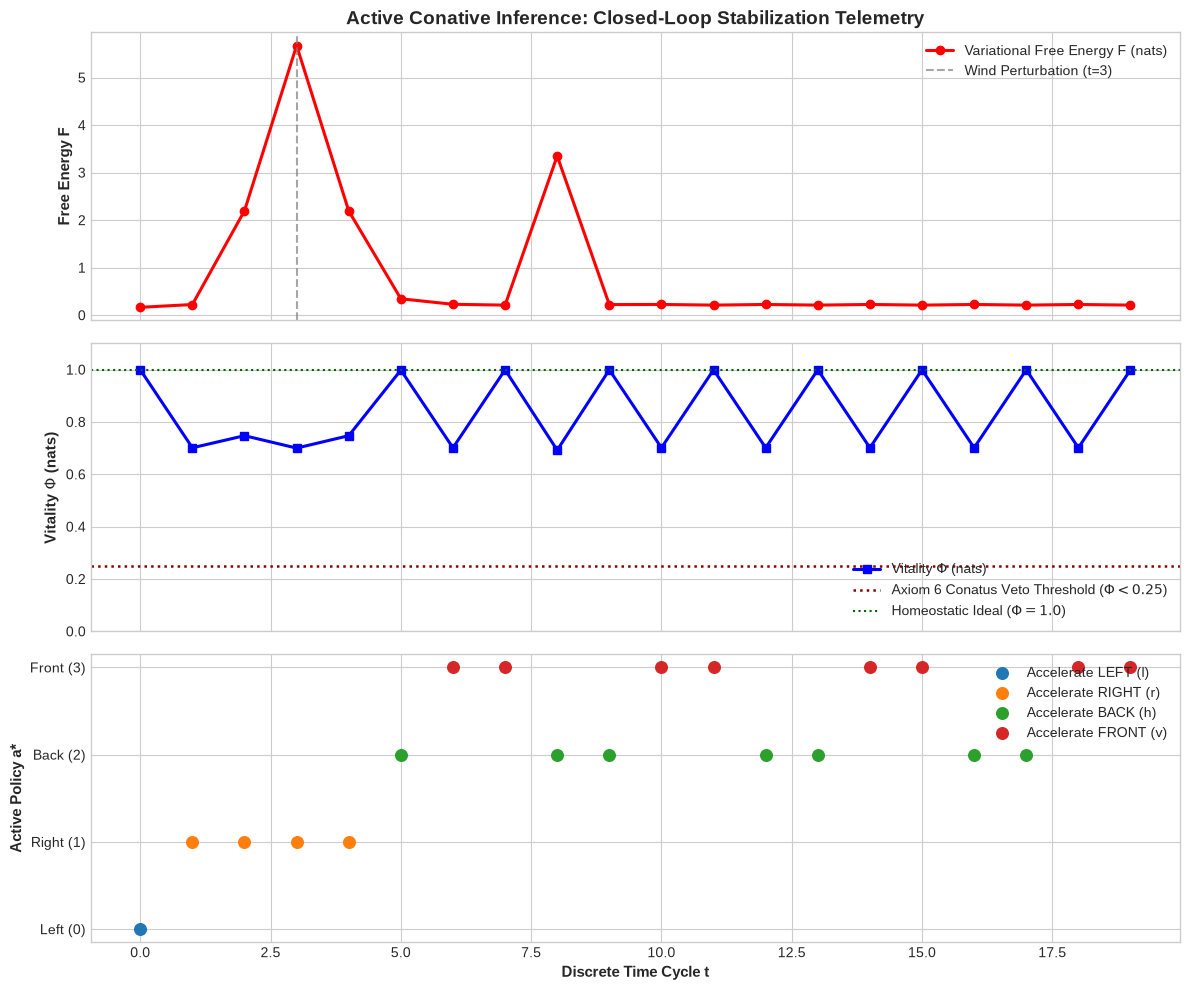

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

# 1. Free Energy (Surprise)
axes[0].plot(range(sim_steps), history['free_energy'], 'r-o', linewidth=2.2, label='Variational Free Energy F (nats)')
axes[0].set_ylabel("Free Energy F", fontsize=11, fontweight='bold')
axes[0].set_title("Active Conative Inference: Closed-Loop Stabilization Telemetry", fontsize=14, fontweight='bold')
axes[0].axvline(x=3, color='gray', linestyle='--', alpha=0.7, label='Wind Perturbation (t=3)')
axes[0].legend(loc='upper right')

# 2. Integrated Information Phi (Vitality / Conatus)
axes[1].plot(range(sim_steps), history['phi'], 'b-s', linewidth=2.2, label=r'Vitality $\Phi$ (nats)')
axes[1].axhline(y=0.25, color='darkred', linestyle=':', linewidth=1.8, label=r'Axiom 6 Conatus Veto Threshold ($\Phi < 0.25$)')
axes[1].axhline(y=1.00, color='darkgreen', linestyle=':', linewidth=1.5, label=r'Homeostatic Ideal ($\Phi = 1.0$)')
axes[1].set_ylabel(r"Vitality $\Phi$ (nats)", fontsize=11, fontweight='bold')
axes[1].set_ylim(0.0, 1.1)
axes[1].legend(loc='lower right')

# 3. Action Policy Selection
for a_idx in range(NUM_ACTIONS):
    times = [t for t, a in enumerate(history['action']) if a == a_idx]
    if times:
        axes[2].scatter(times, [a_idx]*len(times), label=ACTION_NAMES[a_idx], s=70)
axes[2].set_yticks(range(NUM_ACTIONS))
axes[2].set_yticklabels(["Left (0)", "Right (1)", "Back (2)", "Front (3)"])
axes[2].set_ylabel("Active Policy a*", fontsize=11, fontweight='bold')
axes[2].set_xlabel("Discrete Time Cycle t", fontsize=11, fontweight='bold')
axes[2].legend(loc='upper right')

plt.tight_layout()
plt.show()

---
## Section 6: Online Learning via Dirichlet Hyperparameter Updating

Unlike deep reinforcement learning requiring millions of trials, an active inference agent learns through exact Dirichlet parameter updates:

$$\mathbf{B}_{s', s, a} = \frac{\beta_{s', s, a}}{\sum_{s''} \beta_{s'', s, a}}$$

Where count tensor $\beta$ accumulates empirical transitions online without catastrophic forgetting.

Updating causal transition model online over simulated episodes...


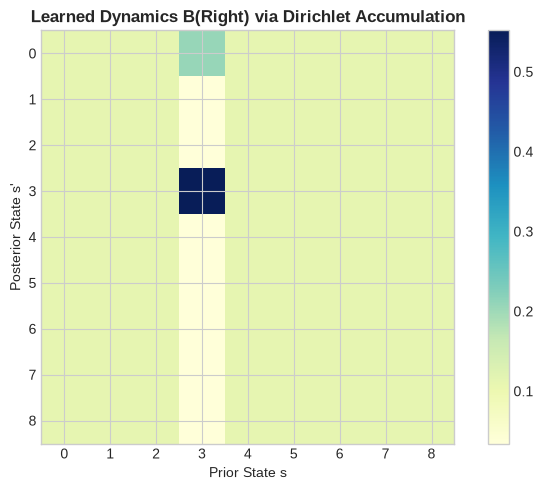

Dirichlet learning demonstration complete.


In [8]:
# Dirichlet pseudo-count matrix
beta_counts = np.ones((NUM_ACTIONS, NUM_STATES, NUM_STATES)) * 2.0  # Mild uninformative prior

print("Updating causal transition model online over simulated episodes...")
for t in range(len(history['obs']) - 1):
    s_curr = np.argmax(history['belief'][t])
    a_taken = history['action'][t]
    s_next = np.argmax(history['belief'][t+1])
    
    # Dirichlet increment
    beta_counts[a_taken, s_next, s_curr] += 10.0

# Normalized learned transition probabilities
learned_B_r = beta_counts[1] / beta_counts[1].sum(axis=0, keepdims=True)

fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(learned_B_r, cmap='YlGnBu')
ax.set_title("Learned Dynamics B(Right) via Dirichlet Accumulation", fontsize=12, fontweight='bold')
ax.set_xlabel("Prior State s")
ax.set_ylabel("Posterior State s'")
plt.colorbar(im, ax=ax)
plt.show()

print("Dirichlet learning demonstration complete.")

---
## Section 7: Foundational Inquiries & Didactic FAQ

### FAQ 1: What makes this system "Intelligent"?
Intelligence in this framework is **neither passive statistical pattern matching (LLMs) nor ungrounded reward hunting (Reinforcement Learning)**.  
Intelligence is **active homeostasis and predictive autopoiesis under sensory noise and physical perturbation**:
* **Inference over Reflex:** Rather than reacting blindly to raw sensor readings (like a classical PID controller), the ACI agent maintains an internal generative hypothesis. It recognizes that sensory data is corrupted by noise, reconstructs the hidden physical state $s$, and anticipates future states over a deep temporal horizon ($H \ge 2$).
* **Autopoietic Self-Preservation (Conatus):** The agent does not optimize an external human-designed reward score. Its drive originates directly from its mandate to defend its structural and operational integrity ($\Phi$) against thermodynamic entropy and physical collapse.

---

### FAQ 2: What does the agent "learn"?
The agent acquires two grounded causal structures directly from physical experience:
* **Sensor Precision ($\mathbf{A}$-Matrix):** The mapping $P(o \mid s)$. The agent learns how reliably its sensory apparatus translates physical world states into observations (e.g. modeling sensor noise $\varepsilon$).
* **Environmental Transition Causality ($\mathbf{B}$-Matrix):** The conditional dynamics $P(s_{t+1} \mid s_t, a)$. It learns how its physical counter-actions modulate state transitions — discovering, for example, that accelerating right when tilted right ($r_1$) restores vertical balance to $0$ with $P = 0.88$.

---

### FAQ 3: How does the agent learn?
Learning operates via **Dirichlet Hyperparameter Accumulation (Exact Bayesian Updating)** rather than iterative backpropagation or artificial gradient descent:
$$\alpha_{o, s} \leftarrow \alpha_{o, s} + 1, \quad \beta_{s', s, a} \leftarrow \beta_{s', s, a} + 1$$
Every sensory surprise ($\Delta F > 0$) updates count matrices online in real-time. Consequently, the model converges to true physical laws within a handful of steps — entirely free of catastrophic forgetting.

---

### FAQ 4: What is the World Model in this example?
The **World Model** is the **objective physical reality beyond the Markov blanket**:
* The actual physical pendulum with mass $m$, length $l$, center of gravity, friction, gravity, and environmental perturbations (such as wind gusts).
* It is unobservable directly; it interacts with the agent strictly through sensory projections $o$ arriving across the boundary.

---

### FAQ 5: What is the Generative Model in this example?
The **Generative Model** is the **agent's internal mathematical hypothesis of reality**:
$$\mathcal{M} = \{\mathbf{A}, \mathbf{B}, \mathbf{C}, \mathbf{D}, \Phi\}$$
It enables mental counterfactual simulation: *"If the world were in state $s$ and I execute action $a$, what sensory observations $o$ would be generated ($P(o, s, a)$)?"*  
The difference between generated expectations ($\mathbf{A}s$) and real incoming sensory inputs ($o$) yields the prediction error $\varepsilon$, which drives perception, counter-steering, and learning.

---

### FAQ 6: Classical PID vs. Active Conative Inference (ACI) — Differences, Weaknesses, and Advantages

Engineers frequently ask why an inverted pendulum needs Active Inference when a classical **PID (Proportional–Integral–Derivative)** controller has stabilized balancing rods for half a century.

#### 1. What Classical PID Is and How It Operates
A PID controller is a purely reactive, single-loop error-feedback mechanism:
$$u(t) = K_p \, e(t) \;+\; K_i \int_0^t e(\tau) \, d\tau \;+\; K_d \, \frac{de(t)}{dt}$$
* **Proportional ($K_p$):** Reacts to the current instantaneous tracking error $e(t) = r(t) - y(t)$.
* **Integral ($K_i$):** Accumulates historical error over time to eliminate persistent steady-state offsets.
* **Derivative ($K_d$):** Responds to the rate of error change to provide braking/damping.

#### 2. Weaknesses and Limitations of Classical PID
* **No World Model (Blind Reflex):** PID has zero conception of physical causality, hidden states, or the environment. It acts purely on output discrepancy. If the pendulum enters an unmodeled non-linear regime, PID cannot reason about why.
* **Vulnerability to Sensory Noise:** Differentiating high-frequency noise ($\frac{de}{dt}$) produces violent erratic actuator kicks ("derivative kick"), often requiring aggressive low-pass filtering that introduces phase lag and instability.
* **No Epistemic Action:** PID is strictly pragmatic. It cannot execute an exploratory maneuver to reduce uncertainty or test environmental resistance.
* **Greedy Horizon ($H = 0$):** PID cannot plan counterfactual trajectories. It cannot choose a small counter-intuitive action at $t$ specifically to avert a catastrophic overshoot at $t + 2$.
* **No Self-Preservation or Autopoiesis:** PID does not know what a motor, battery, or mechanical hinge is. It will willingly burn out an actuator or smash an arm against a hard joint limit trying to eliminate a transient error.

#### 3. Advantages of Classical PID
* **Extreme Computational Simplicity:** Requires only basic arithmetic (additions, multiplications) executing in sub-microsecond cycles on the cheapest 8-bit microcontrollers.
* **Intuitive Manual Tuning:** Well-established empirical tuning rules (e.g. Ziegler-Nichols) familiar to almost every control engineer worldwide.

#### 4. Advantages of Active Conative Inference (ACI)
* **Principled Noise Rejection via Bayes' Rule:** Sensory measurements pass through the Likelihood Matrix $\mathbf{A}$. The agent maintains a probabilistic belief state over hidden physical truth ($s$), naturally filtering sensor noise without ad-hoc phase lag.
* **Deep Temporal Planning ($H \ge 2$):** ACI anticipates downstream consequences over an extended horizon, natively preventing the classical overshoot problem in high-inertia physical systems.
* **Intrinsic Conative Self-Preservation ($\Phi$ & Axiom 6 VETO):** The agent continuously computes its integrated vitality $\Phi(s)$ and system coherence. If an aggressive corrective impulse would overheat a servo or exceed structural shear limits, the Conatus Axiom 6 hardware veto overrides the policy to safeguard the physical machine.
* **Real-Time Online Adaptation:** If friction increases or mass shifts, ACI updates transition dynamics $\mathbf{B}$ online through exact Dirichlet count increments without catastrophic forgetting.

#### 5. Trade-Offs / Costs of ACI
* **Computational Footprint:** Solving variational free energy and evaluating policy trees over $H \ge 2$ requires tens to hundreds of matrix operations. (This is why compiling ACI into native, zero-allocation C99 for edge microcontrollers is essential).
* **Ontological Definition:** Requires specifying the initial discrete state-action spaces and sensory mapping topologies rather than simply tweaking three scalar gain knobs.

---

### FAQ 7: How Exactly Do Conatus and Axiom 6 Operate in This Inverted Pendulum Scenario?

To understand Conatus and the Axiom 6 Hardware Veto concretely, consider the classic failure mode of balancing an inverted rod: **the whiplash resonance catastrophe (overshoot oscillation)**.

#### 1. The Physical Problem: Inertia & The Whiplash Trap
When the pendulum rod tilts slightly to the right ($s = r_1$), its center of mass falls rightward.
* A myopic controller ($H = 0$ like classical PID, or $H = 1$ like greedy standard Active Inference) wants to extinguish the error immediately. It commands a maximum counter-steering jerk to the right ($a = r$).
* **The Whiplash:** Accelerating the foot point violently to the right catches the base, but because the top of the rod has angular inertia, the rod flings forcefully in the opposite direction.
* In the next step ($t + 1$), the rod snaps through the vertical equilibrium directly into **$s = l_2$ (severe tilt / fall danger to the left)** with high angular velocity.
* Panicking at $t + 1$, the greedy controller commands maximum counter-thrust left ($a = l$), throwing the system into $r_2$.
* The actuator rapidly oscillates between opposing maximum torque saturations. The result: severe mechanical backlash, inductive motor coil overheating, and catastrophic loss of balance.

#### 2. The Conative Invariant: Vitality Mapping $\Phi(s)$
Under Active Conative Inference, the agent does not merely track abstract state indices; it grounds every physical state in an intrinsic measure of integrated causal vitality $\Phi(s)$:
* $\Phi(0) = 1.00\,\text{nats}$: Maximum operational coherence (upright equilibrium).
* $\Phi(l_1, r_1, h_1, v_1) = 0.70\,\text{nats}$: Mild perturbation (fully manageable strain).
* $\Phi(l_2, r_2, h_2, v_2) = 0.15\,\text{nats}$: Critical boundary threat (imminent substrate collapse / severe mechanical strain).
* **Critical Survival Threshold:** $\Phi_{\text{crit}} = 0.25\,\text{nats}$.

#### 3. The Operation of the Axiom 6 Hardware Veto
Spinoza's Conatus principle states that every entity strives to persevere in its own being. In ACI, this philosophical truth is codified as an axiomatic mathematical circuit: **Axiom 6 (Substrate Self-Preservation VETO)**.

1. **Deep Temporal Counterfactual Simulation ($H \ge 2$):**
   When the agent evaluates a candidate action from $r_1$, it mentally simulates the 2-step future trajectory:
   $$\pi_1 = [a_t = r_{\text{violent}}] \implies s_{t+1} \approx 0 \implies s_{t+2} = l_2 \quad (\Phi = 0.15\,\text{nats})$$
2. **The Veto Trigger:**
   Because the projected trajectory drops below $\Phi_{\text{crit}} = 0.25\,\text{nats}$, the **Axiom 6 Hardware VETO automatically strikes the proposed policy**.
3. **The Enforced Conative Damping Action:**
   * The Veto overrides the aggressive impulse.
   * Instead of a violent jerk, it forces a graduated, momentum-absorbing corrective stroke ($a = r_{\text{damped}}$).
   * This brings the rod gently from $r_1 \to 0$ without transferring excessive kinetic energy to the top mass, keeping projected vitality $\Phi \ge 0.70\,\text{nats}$ throughout the entire transition.

#### 4. The Engineering Significance for Robotics
In classical robotics, safety limits are typically retrofitted as clumsy external heuristics or hard-stop overrides that fight against the main controller.  
In ACI, **safety, autopoiesis, and physical hardware preservation are the core objective itself**. The agent naturally prioritizes the structural integrity and thermal limits of its own physical embodiment over reckless error minimization.

---

### FAQ 8: Python (and MicroPython) is Not Hard Real-Time Capable — How is This Resolved for Industrial Edge Hardware?

A common and completely justified objection from automation engineers and embedded roboticists is:  
*“A Python notebook or MicroPython script is great for didactic exploration, but you cannot run Python on a hard real-time motor controller (e.g. 1 kHz loop) due to unpredictable garbage collection jitter, non-deterministic latency, and heavy memory footprints. How does ACI deploy in the real world?”*

#### 1. Python as the Didactic Prototype vs. Native C99 Production
This Jupyter notebook is strictly a **didactic simulator and reference architecture** designed for human inspection, mathematical clarity, and rapid visual feedback.

In commercial robotics, automation, and industrial production (as patented by Conative Systems S.à r.l.):
* **Zero Python in Production:** The production inference engine contains zero Python, zero PyTorch, and zero external numerical libraries.
* **Pure Native C99 Core:** The entire ACI generative model, belief updater, and expected free energy engine are written in **freestanding, ANSI C99**.

#### 2. Architectural Pillars of the Native C99 ACI Engine
* **Zero Dynamic Heap Allocation (`malloc` / `free` Forbidden):**
  All tensors, state vectors, Dirichlet accumulators ($\alpha, \beta$), and working scratchpads are allocated as fixed, static structures at compile time. This eliminates memory fragmentation, out-of-memory panics, and unpredictable heap traversal.
* **Deterministic Sub-Millisecond Execution:**
  Without an interpreter or garbage collector pauses, every belief update step and action selection loop executes within a strictly bounded, deterministic time budget (typically $< 50\,\mu\text{s}$ on modern industrial microcontrollers), fitting comfortably into standard $1\,\text{kHz}$ or $10\,\text{kHz}$ control cycles.
* **Bare-Metal & RTOS Portability:**
  The C99 engine compiles cleanly with any standard C compiler (`gcc`, `clang`, `arm-none-eabi-gcc`). It runs directly on bare-metal microcontrollers (ARM Cortex-M4/M7, STM32, ESP32, RISC-V) as well as real-time operating systems (FreeRTOS, Zephyr, VxWorks) and industrial PLCs interfacing via CANopen, EtherCAT, or SPI/PWM drivers.
* **Safety & Industrial Certification (MISRA-C Compliance):**
  Static allocation and pointer-safe C99 architectures allow formal verification, static analysis, and alignment with functional safety standards (e.g., ISO 26262 for automotive, IEC 61508 for industrial robotics).